# Домашнее задание по теме «Логистическая регрессия и SVM»

В домашней работе ты реализуешь логистическую регрессию, сравнишь преобразования целевой переменной и проверишь калибровку вероятностей.

**Максимальная оценка: 10 баллов.** Задания 1–8 дают соответственно 2, 1,5, 0,5, 1,5, 0,5, 2, 1 и 1 балл. Баллы подзадач входят в оценку задания и не суммируются с ней повторно. Задания со звёздочкой входят в этот максимум.

## Логистическая регрессия

Реализуй бинарную логистическую регрессию без регуляризации. Вычисляй градиенты сразу по всей выборке, без циклов по объектам. Цикл по итерациям градиентного спуска нужен. Затем проверь модель на Wine и построй границы для пар признаков. Проверки ниже охватывают основные свойства реализации, но не доказывают корректность на любых данных.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split

# Загружаем данные
data = load_wine()
X = data.data
y = data.target
# Оставляем только объекты классов 0 и 1
mask = y < 2
X = X[mask]
y = y[mask]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
feature_names = data.feature_names
# Масштабирование обучаем только на train.
X_train_raw, X_test_raw = X_train.copy(), X_test.copy()
scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

### Задание 1 [2 балла]

Напиши класс `LogisticRegression`. Используй среднюю бинарную кросс-энтропию и полный градиент по train. В `fit` заново инициализируй веса, очисти `losses` и сохраняй потерю после каждой итерации. Метод возвращает `self`. Для устойчивого вычисления потерь по логитам используй `np.logaddexp(0, z) - y*z`.

In [2]:
class LogisticRegression:
    def __init__(self, lr=0.01, iterations=1000):
        self.lr = lr
        self.iterations = iterations
        self.w = None
        self.b = None
        self.losses = []

    def initialize_parameters(self, X):
        """
        Инициализирует веса и смещение нулями
        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки
        На выходе:
            ничего не возвращает
        """
        # Напиши код здесь
        self.w = np.zeros(np.shape(X)[1])
        self.b = 0
        self.losses = []

    def _sigmoid(self, z):
        """
        Вычисляет сигмоидную функцию активации: 1 / (1 + e^(-z))
        Принимает:
            z (ndarray): входные значения
        Возвращает:
            sigmoid (ndarray): значения после сигмоиды
        """
        z = np.clip(z, -500, 500)  # Ограничиваем значения, чтобы избежать переполнения
        # Напиши код здесь
        return 1 / (1 + np.exp(-z))

    def compute_loss(self, X, y):
        """
        Вычисляет функцию потерь: бинарная кросс-энтропия
            L = -1/n * Σ(y*log(p) + (1-y)*log(1-p))
            Подсказка: используй np.mean(np.logaddexp(0, z) - y*z)
        Принимает:
            X (ndarray): массив признаков
            y (ndarray): вектор меток классов (0 или 1)
        Возвращает:
            loss (float): значение функции потерь
        """
        # Напиши код здесь
        z = np.dot(X, self.w) + self.b
        return np.mean(np.logaddexp(0, z) - y * z)

    def step(self, X, y):
        """
        Один шаг градиентного спуска по всей выборке

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки
            y (ndarray): метки классов (0 или 1)

        Возвращает:
            ничего не возвращает, обновляет веса и смещение
        """
        # Напиши код здесь
        m = X.shape[0]

        z = np.dot(X, self.w) + self.b
        y_pred = self._sigmoid(z)

        error = y_pred - y
        dw = (1 / m) * np.dot(X.T, error)
        db = (1 / m) * np.sum(error)

        self.w -= self.lr * dw
        self.b -= self.lr * db

    def fit(self, X, y):
        """
        Обучает логистическую регрессию на тренировочных данных

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки
            y (ndarray): метки классов (0 или 1)

        Возвращает:
            self: обученный объект
        """
        # Напиши код здесь
        self.initialize_parameters(X)
        for i in range(self.iterations):
          self.step(X, y)
          self.losses.append(self.compute_loss(X, y))
        return self

    def predict_proba(self, X):
        """
        Делает вероятностное предсказание

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки

        Возвращает:
            probs (ndarray): предсказанные вероятности классов
        """
        z = np.dot(X, self.w) + self.b
        probs = self._sigmoid(z)
        return np.vstack([1 - probs, probs]).T

    def predict(self, X):
        """
        Делает бинарное предсказание: класс 0 или 1

        Принимает:
            X (ndarray, shape: [n_samples, n_features]): обучающие признаки

        Возвращает:
            preds (ndarray): предсказанные метки классов
        """
        # Напиши код здесь
        preds = (self._sigmoid(np.dot(X, self.w) + self.b) >= 0.5).astype(int)
        return preds

Проверь формы массивов, значения сигмоиды и работу основных методов. Для обучения далее используем масштабированные признаки.

In [3]:
import numpy as np

model = LogisticRegression()
model.initialize_parameters(X_train)

# Проверка initialize_parameters
assert model.w.shape == (X_train.shape[1],), "Ошибка: некорректная размерность весов w"
assert np.all(model.w == 0), "Ошибка: веса должны быть инициализированы нулями"
assert model.b == 0, "Ошибка: смещение должно быть инициализировано нулём"
print("Модуль initialize_parameters работает корректно")

# Проверка _sigmoid
z_test = np.array([0, 2])
sigmoid_vals = model._sigmoid(z_test)
assert np.allclose(sigmoid_vals, [0.5, 1 / (1 + np.exp(-2))]), "Ошибка: сигмоида рассчитывается некорректно"
print("Модуль _sigmoid работает корректно")

# Проверка compute_loss
loss = model.compute_loss(X_train, y_train)
assert isinstance(loss, float), "Ошибка: функция потерь должна возвращать число"
assert np.isclose(loss, np.log(2)), "При нулевых весах потеря должна равняться log(2)"
print("Модуль compute_loss работает корректно")

# Проверка step
old_w = model.w.copy()
old_b = model.b
model.step(X_train, y_train)

assert not np.allclose(model.w, old_w), "Ошибка: веса не изменились после шага градиентного спуска"
assert model.w.shape == old_w.shape, "Ошибка: форма весов изменилась после обновления"
assert model.b != old_b, "Ошибка: смещение не обновилось"
print("Модуль step работает корректно")

# Проверка fit
model.fit(X_train, y_train)
assert model.w is not None, "Ошибка: веса не определены после обучения"
assert model.b is not None, "Ошибка: смещение не определено после обучения"
print("Модуль fit работает корректно")

# Проверка predict
preds = model.predict(X_test)
assert preds.shape == y_test.shape, "Ошибка: размерность предсказаний не совпадает с y_test"
assert set(np.unique(preds)).issubset({0, 1}), "Ошибка: предсказания должны быть бинарными (0 или 1)"
print("Модуль predict работает корректно")

assert len(model.losses) == model.iterations
assert model.losses[-1] < model.losses[0]
assert np.allclose(model.predict_proba(X_test).sum(axis=1), 1)
model.fit(X_train, y_train)
assert len(model.losses) == model.iterations, "История должна сбрасываться при повторном fit"
print("Все тесты пройдены")
assert np.isclose(model.losses[-1], model.compute_loss(X_train, y_train))


Модуль initialize_parameters работает корректно
Модуль _sigmoid работает корректно
Модуль compute_loss работает корректно
Модуль step работает корректно
Модуль fit работает корректно
Модуль predict работает корректно
Все тесты пройдены


In [4]:
# Проверим, что модель работает

model = LogisticRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)

print(preds)

[0 0 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 1 1 1 0 0 1 0 1 0 1 1 0 0 0 0 0 0 1 1 1
 0 1 0 0 1 1 0 1 1 0 0 0 1 1 0]


### Задание 2 [1,5 балла]

Построй границы для всех пар признаков Wine. Для каждой пары обучи `StandardScaler` на `X_train_raw[:, [i, j]]`, преобразуй train и обучи свою логистическую регрессию. Сетку создавай в исходных единицах и преобразуй тем же scaler перед `predict_proba`.

Используй `XX, YY = np.meshgrid(xx, yy)`, фон вероятностей со шкалой от 0 до 1 и линию уровня 0,5. На рисунке покажи объекты train. Разбей 78 пар на несколько рисунков, чтобы подписи оставались читаемыми. Это иллюстрация работы моделей на train, а не оценка качества на новых данных.

In [5]:
# Напиши код здесь
from itertools import combinations

def plot_logreg_boundaries_all_pairs(X_train_raw, y_train, feature_names,
                                     LogisticRegressionClass,
                                     lr=0.1, iterations=2000,
                                     pairs_per_fig=6, n_cols=3,
                                     grid_steps=200, margin=0.5):
    n_features = X_train_raw.shape[1]
    all_pairs = list(combinations(range(n_features), 2))

    for fig_start in range(0, len(all_pairs), pairs_per_fig):
        chunk = all_pairs[fig_start:fig_start + pairs_per_fig]
        n_rows = int(np.ceil(len(chunk) / n_cols))

        fig, axes = plt.subplots(n_rows, n_cols,
                                 figsize=(5 * n_cols, 4 * n_rows))
        axes = np.array(axes).reshape(-1)

        for ax_idx, (i, j) in enumerate(chunk):
            ax = axes[ax_idx]

            X_pair_raw = X_train_raw[:, [i, j]]

            scaler_pair = StandardScaler().fit(X_pair_raw)
            X_pair = scaler_pair.transform(X_pair_raw)

            model = LogisticRegressionClass(lr=lr, iterations=iterations)
            model.fit(X_pair, y_train)

            x_min = X_pair_raw[:, 0].min() - margin * np.std(X_pair_raw[:, 0])
            x_max = X_pair_raw[:, 0].max() + margin * np.std(X_pair_raw[:, 0])
            y_min = X_pair_raw[:, 1].min() - margin * np.std(X_pair_raw[:, 1])
            y_max = X_pair_raw[:, 1].max() + margin * np.std(X_pair_raw[:, 1])

            xx = np.linspace(x_min, x_max, grid_steps)
            yy = np.linspace(y_min, y_max, grid_steps)
            XX, YY = np.meshgrid(xx, yy)

            grid_raw = np.c_[XX.ravel(), YY.ravel()]
            grid_scaled = scaler_pair.transform(grid_raw)
            probs = model.predict_proba(grid_scaled)[:, 1].reshape(XX.shape)

            cf = ax.contourf(XX, YY, probs, levels=np.linspace(0, 1, 21),
                             cmap='RdBu_r', vmin=0, vmax=1, alpha=0.8)

            ax.contour(XX, YY, probs, levels=[0.5],
                       colors='k', linewidths=2)

            for cls, color in zip([0, 1], ['#0000FF', '#FF0000']):
                m = y_train == cls
                ax.scatter(X_pair_raw[m, 0], X_pair_raw[m, 1],
                           c=color, edgecolors='k', s=30,
                           label=f'class {cls}')

            ax.set_xlabel(feature_names[i], fontsize=9)
            ax.set_ylabel(feature_names[j], fontsize=9)
            ax.set_title(f'{feature_names[i]}\nvs {feature_names[j]}',
                         fontsize=9)
            ax.legend(fontsize=7, loc='best')

        for ax_idx in range(len(chunk), len(axes)):
            axes[ax_idx].axis('off')

        fig.colorbar(cf, ax=axes.tolist(), shrink=0.8,
                     label='P(class = 1)')

        fig.suptitle(
            f'Границы логистической регрессии (train), '
            f'пары {fig_start + 1}–{fig_start + len(chunk)} из {len(all_pairs)}',
            fontsize=12, y=1.0)
        plt.show()

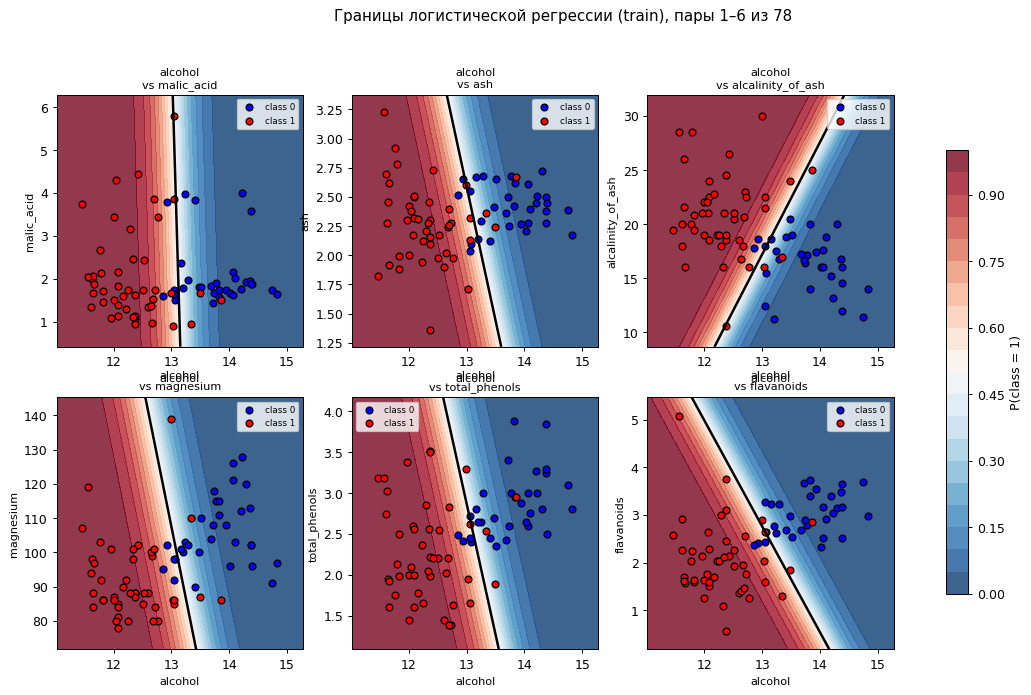

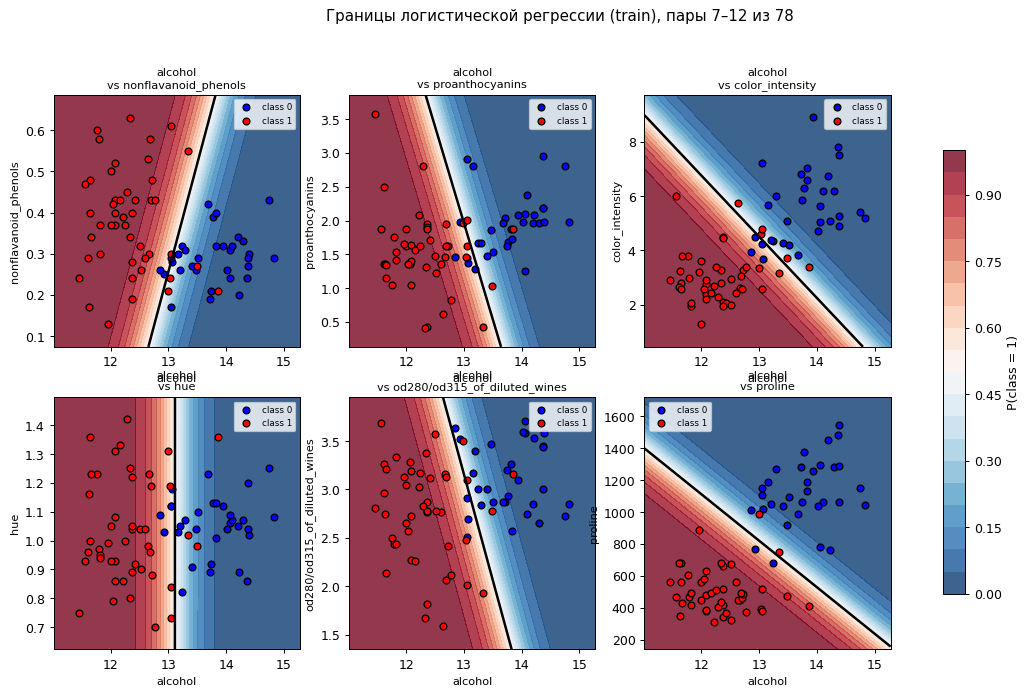

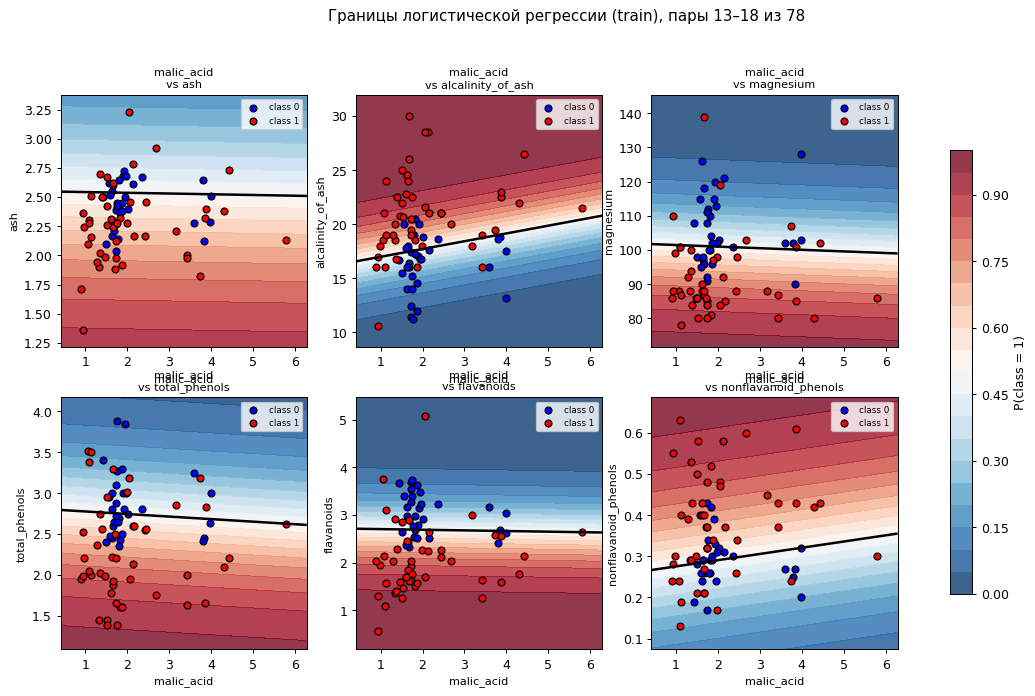

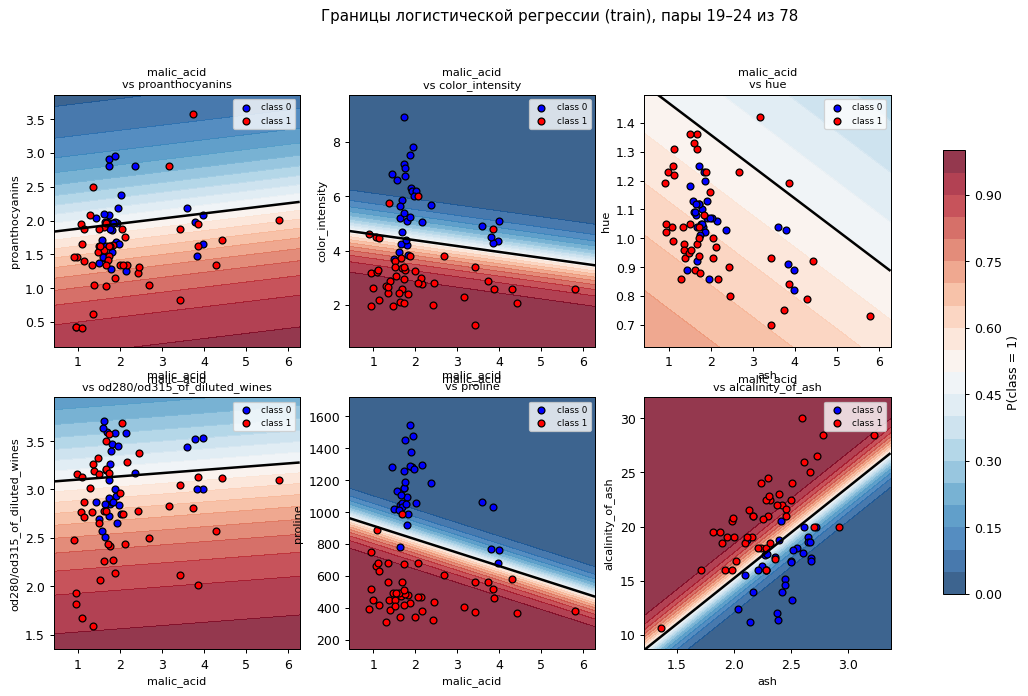

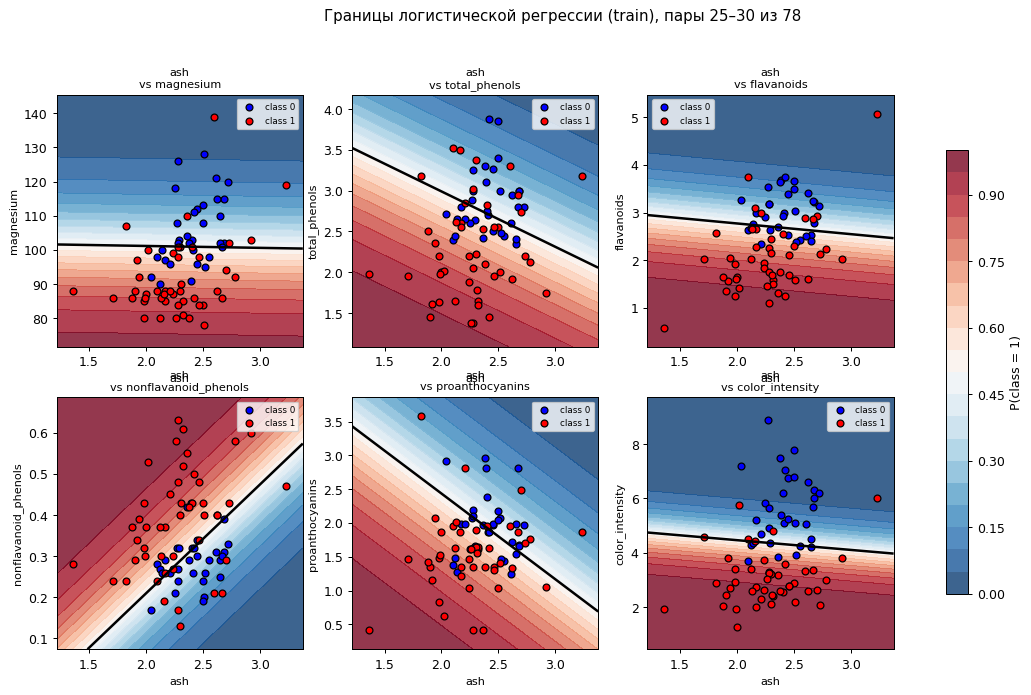

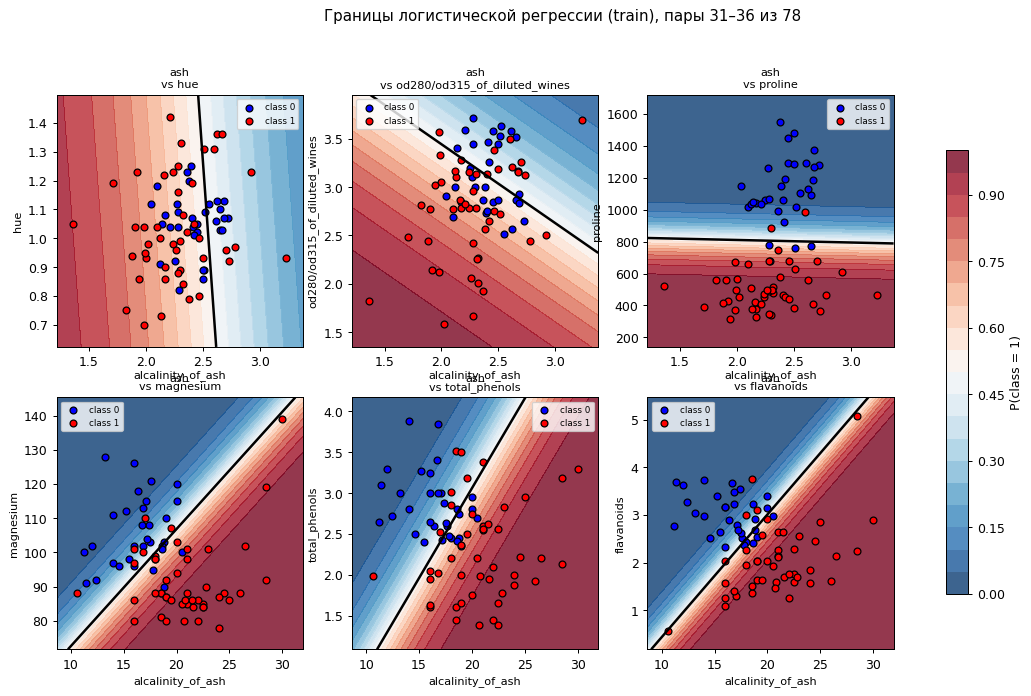

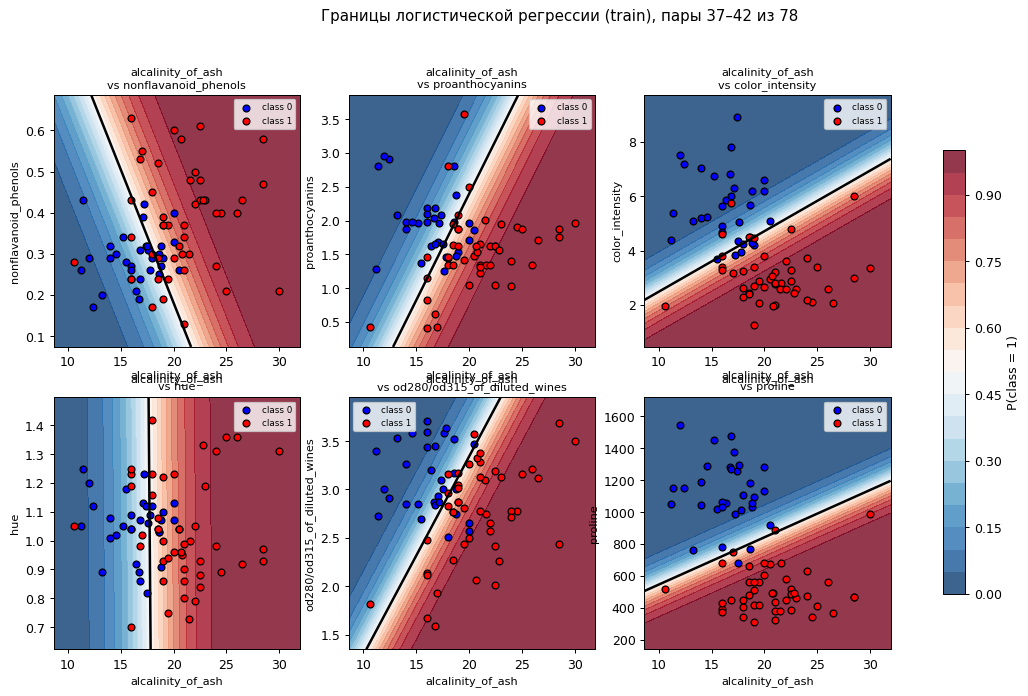

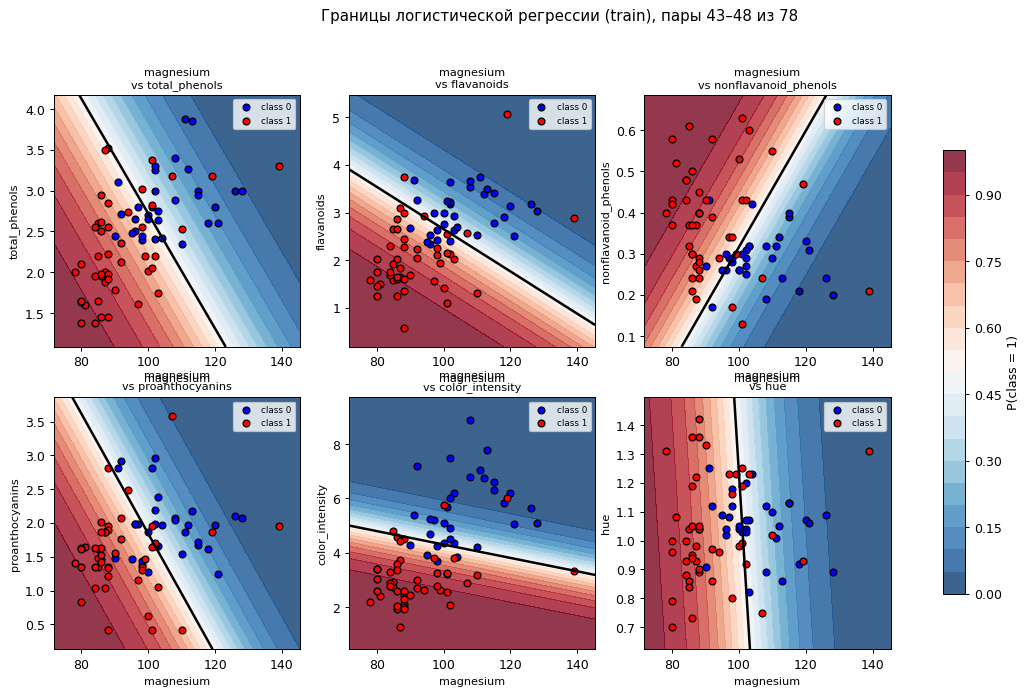

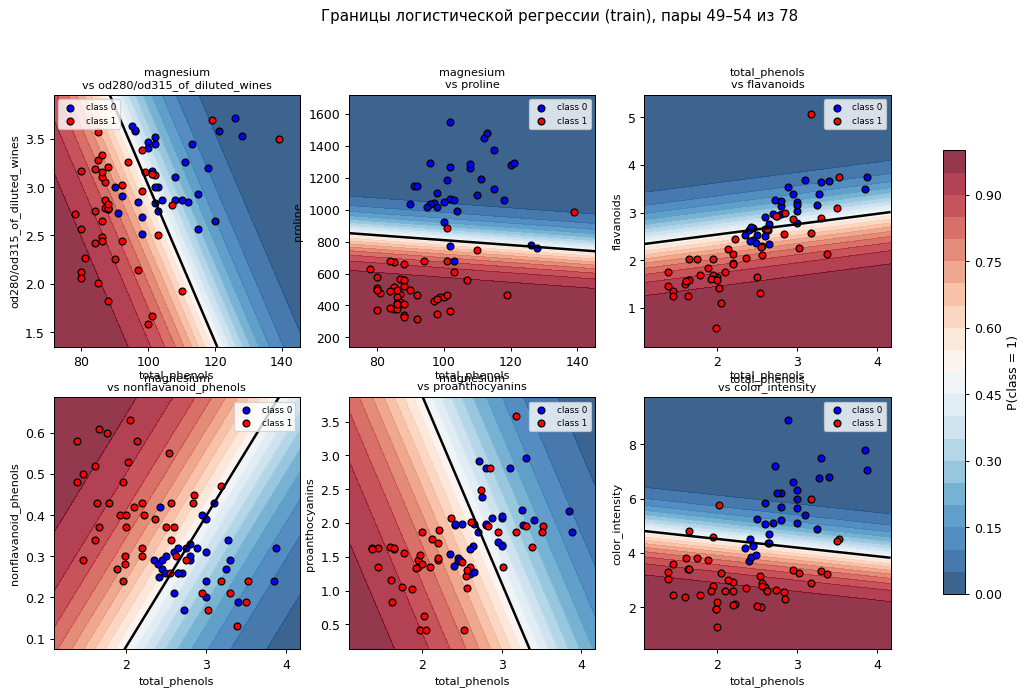

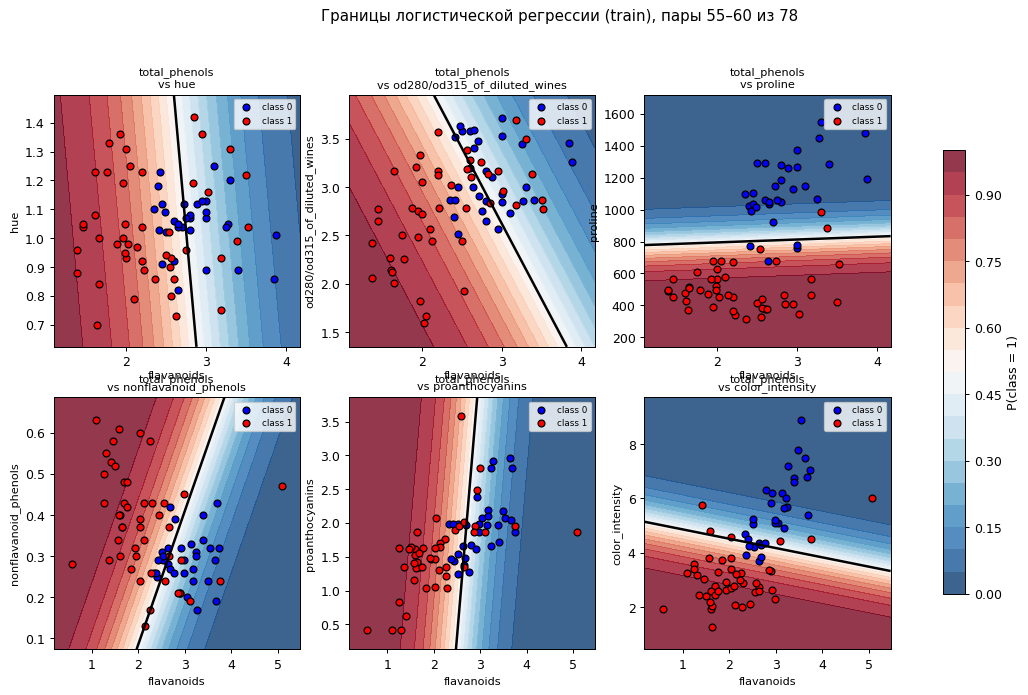

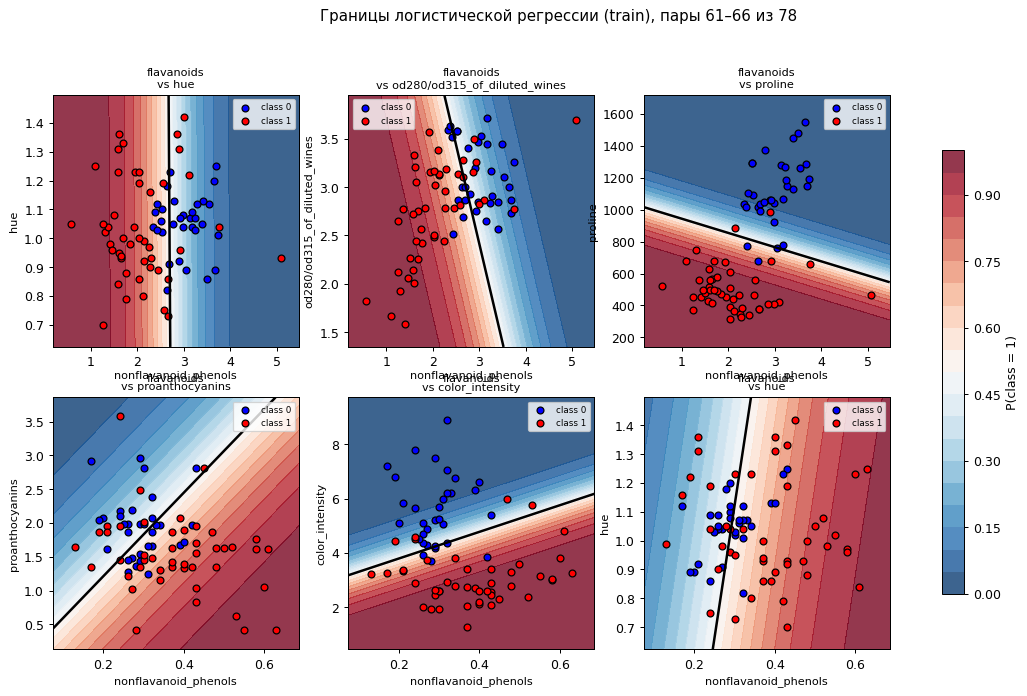

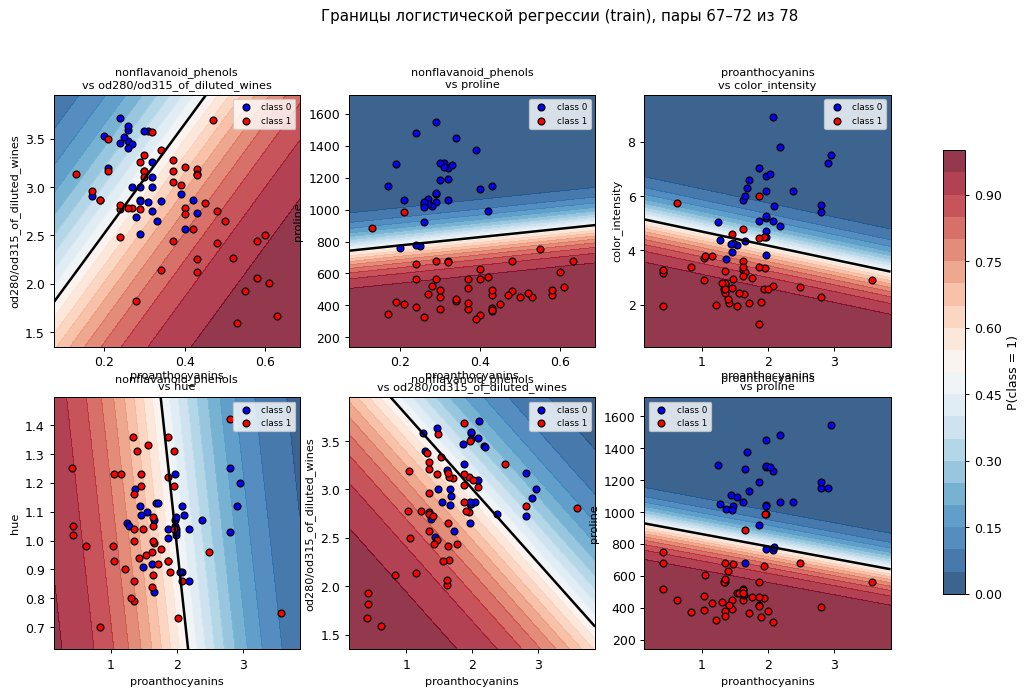

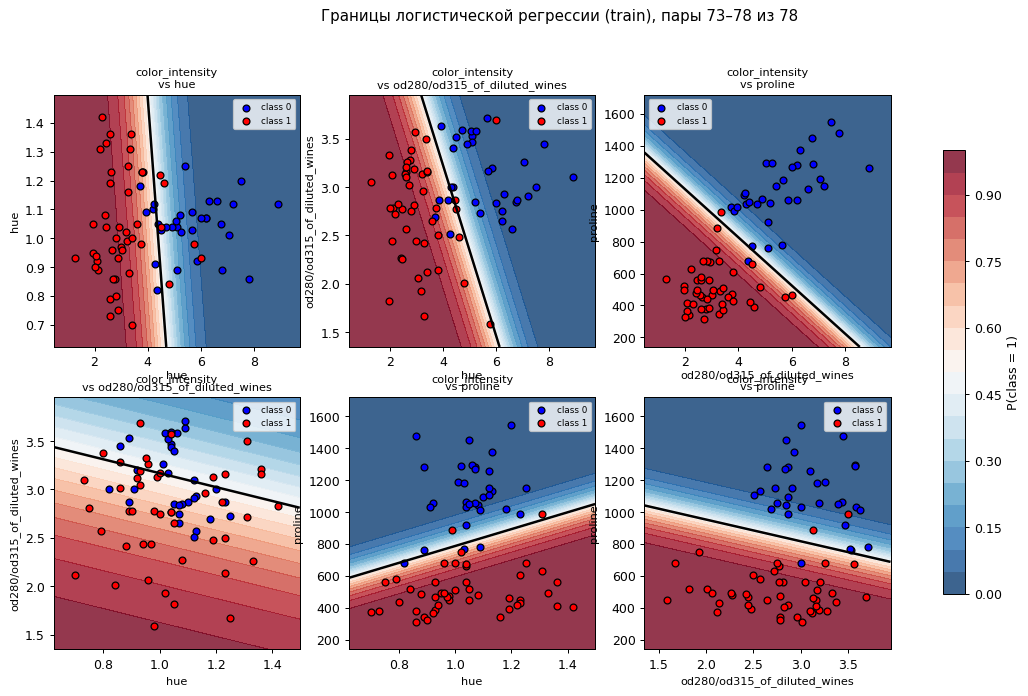

In [6]:
plot_logreg_boundaries_all_pairs(X_train_raw, y_train, feature_names, LogisticRegression)

**Вопросы.** Назови две пары, для которых прямая хорошо разделяет классы на train, и две пары с заметным перекрытием. Может ли нелинейная граница помочь при перекрытии? Как проверить эту гипотезу на новых объектах?

In [7]:
# Вспомогательное сравнение пар на train для ответа по графикам.
from sklearn.metrics import accuracy_score
pair_rows = []
for i, j in combinations(range(X_train_raw.shape[1]), 2):
    pair_X = StandardScaler().fit_transform(X_train_raw[:, [i, j]])
    pair_model = LogisticRegression(lr=0.1, iterations=2000).fit(pair_X, y_train)
    pair_rows.append({"Пара": f"{feature_names[i]} + {feature_names[j]}",
                      "Accuracy train": accuracy_score(y_train, pair_model.predict(pair_X))})
pair_results = pd.DataFrame(pair_rows).sort_values("Accuracy train", ascending=False)
print("Две пары с хорошим линейным разделением на train:")
display(pair_results.head(2))
print("Две пары с заметным перекрытием для линейной границы:")
display(pair_results.tail(2))

Две пары с хорошим линейным разделением на train:
Две пары с заметным перекрытием для линейной границы:


,Пара,Accuracy train
74,color_intensity + proline,0.974359
22,malic_acid + proline,0.974359


,Пара,Accuracy train
30,ash + hue,0.589744
20,malic_acid + hue,0.564103


**Ответ.** Хорошо разделяются пары `color_intensity + proline` и `malic_acid + proline` (train accuracy ≈ 0,974). Заметное перекрытие для линейной границы есть у `ash + hue` (≈ 0,590) и `malic_acid + hue` (≈ 0,564). Нелинейная граница может помочь, если классы имеют нелинейную структуру. Если объекты разных классов действительно перекрываются в выбранных двух признаках, усложнение границы не обязательно поможет. Проверять гипотезу следует сравнением линейной модели и, например, SVM с RBF-ядром на одинаковых CV-разбиениях train, обучая масштабирование внутри каждого фолда. После выбора параметров по CV нужно сравнить модели на отложенной test. Train accuracy здесь служит только описанием рисунков, а не оценкой обобщения.

## Target transformation

Сравним линейную регрессию и дерево при четырёх преобразованиях таргета. Все метрики качества будем считать после обратного преобразования в исходных денежных единицах.

### Задание 3 [0,5 балла]

Загрузи Ames Housing (`house_prices`, версия 1), выдели `SalePrice` и исключи служебный `Id`. Сначала раздели данные на train/test с `test_size=0.2, random_state=42`. Создай `ColumnTransformer`: для числовых признаков импутация средним и StandardScaler, для категориальных импутация модой и OneHotEncoder. Здесь создай препроцессор, но не вызывай `fit_transform` до CV.

In [8]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold

ames = fetch_openml(name="house_prices", version=1, as_frame=True)
df = ames.frame
y = df['SalePrice'].to_numpy(dtype=float)
X = df.drop(columns=['SalePrice', 'Id'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Определи categorical_features и numeric_features по X_train.
# Создай preprocessor. Он будет обучаться внутри Pipeline на каждом CV-фолде.
# Напиши код здесь
categorical_features = X_train.select_dtypes(include=['category', 'object']).columns.tolist()
numeric_features = X_train.select_dtypes(include=['integer', 'float']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler',  StandardScaler())
    ]), numeric_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
    ]), categorical_features)
], remainder='passthrough')

### Задание 4 [1,5 балла]

### Задание 4.1 [0,2 балла]

Заполни тело функции `apply_transformations()`. В функции уже реализована базовая версия: «Оригинал» — без преобразования и `log1p(y)` — лог-преобразование. Необходимо добавить ещё два преобразования:
- квадратный корень для неотрицательных цен. При обратном преобразовании отрицательный прогноз в шкале корня ограничь нулём, затем возведи в квадрат.

- Yeo — Johnson, более универсальное преобразование, похожее на Box — Cox, но умеет работать с отрицательными значениями и нулями, для его реализации используй `sklearn.preprocessing.PowerTransformer(method="yeo-johnson")`.

Функция должна возвращать словарь transforms:
- где ключ — название преобразования (строка);
- значение — кортеж из трёх элементов:
   - `y_transformed` — преобразованный `y_train`;
   - `inverse_transform_func` — функция, выполняющая обратное преобразование;
   - `transform_func` — функция, применяющая преобразование (она позволяет проверить прямое и обратное преобразования).

In [9]:
from scipy.stats import boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV


def apply_transformations(y_train):
    y_train = np.asarray(y_train)
    transforms = {
        "Оригинал": (y_train, lambda x: x, lambda x: x),
        "log1p(y)": (np.log1p(y_train), np.expm1, np.log1p)
    }
    # Напиши код здесь
    y_sqrt = np.sqrt(np.maximum(y_train, 0))

    def sqrt_inverse(x):
        return np.square(np.maximum(x, 0))

    def sqrt_transform(x):
        return np.sqrt(np.maximum(x, 0))

    transforms["sqrt"] = (y_sqrt, sqrt_inverse, sqrt_transform)

    pt = PowerTransformer(method="yeo-johnson")
    y_yeojohnson = pt.fit_transform(y_train.reshape(-1, 1)).ravel()

    def yeojohnson_inverse(x):
        return pt.inverse_transform(x.reshape(-1, 1)).ravel()

    def yeojohnson_transform(x):
        return pt.transform(x.reshape(-1, 1)).ravel()

    transforms["yeo-johnson"] = (y_yeojohnson, yeojohnson_inverse, yeojohnson_transform)


    return transforms

### Задание 4.2 [1 балл]

Реализуй `evaluate_model_cv(transform_name, config, X_train, y_train, X_test, y_test)`.

1. Создай преобразователь таргета: `FunctionTransformer` для тождественного преобразования, log1p/expm1 и sqrt/квадрата, `PowerTransformer(method="yeo-johnson")` для Yeo–Johnson.
2. Собери `Pipeline([("preprocess", clone(preprocessor)), ("model", clone(config["estimator"]))])`.
3. Оберни pipeline в `TransformedTargetRegressor(regressor=..., transformer=...)`. Он обучает преобразование y внутри каждого фолда и возвращает прогноз в исходной шкале. Пример имени параметра для GridSearchCV: `regressor__model__max_depth`.
4. Используй одинаковый `KFold(n_splits=5, shuffle=True, random_state=42)` и `scoring="neg_mean_absolute_error"` для всех вариантов. Обучи GridSearchCV на исходном y_train. Препроцессинг X и преобразование y должны обучаться внутри CV.
5. Верни лучшие параметры, среднюю CV MAE, test MAE и test R². Test используется для сравнения заранее заданных вариантов, после просмотра результатов их не перенастраиваем.

`apply_transformations` из предыдущей подзадачи пригодится для рисунка распределений. Функцию, уже обученную на всём y_train, нельзя использовать как готовое преобразование внутри CV.

In [10]:
def evaluate_model_cv(transform_name, config, X_train, y_train, X_test, y_test):
    # Напиши код здесь
    if transform_name == "Оригинал":
        target_transformer = FunctionTransformer(
            func=lambda x: x,
            inverse_func=lambda x: x,
            check_inverse=False
        )
    elif transform_name == "log1p(y)":
        target_transformer = FunctionTransformer(
            func=np.log1p,
            inverse_func=np.expm1,
            check_inverse=False
        )
    elif transform_name == "sqrt":
        target_transformer = FunctionTransformer(
            func=lambda x: np.sqrt(np.maximum(x, 0)),
            inverse_func=lambda x: np.square(np.maximum(x, 0)),
            check_inverse=False
        )
    elif transform_name == "yeo-johnson":
        target_transformer = PowerTransformer(method="yeo-johnson")
    else:
        raise ValueError(f"Неизвестное преобразование: {transform_name}")

    pipeline = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", clone(config["estimator"]))
    ])

    ttr = TransformedTargetRegressor(
        regressor=pipeline,
        transformer=target_transformer
    )

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    grid_search = GridSearchCV(
        estimator=ttr,
        param_grid=config["param_grid"],
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
        verbose=0
    )
    grid_search.fit(X_train, y_train)

    best_params = grid_search.best_params_
    cv_mae = -grid_search.best_score_

    y_test_pred = grid_search.predict(X_test)

    test_mae = mean_absolute_error(y_test, y_test_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    return best_params, cv_mae, test_mae, test_r2

Сравни `LinearRegression` с пустой сеткой параметров и `DecisionTreeRegressor` с сеткой `max_depth=[3, 5, 10]`, `min_samples_split=[2, 5, 10]`. Для обеих моделей используй четыре преобразования: `Оригинал`, `log1p(y)`, `sqrt(y)`, `Yeo–Johnson`. Вызови `evaluate_model_cv` для каждой комбинации и выведи результаты в таблице. Все варианты оцениваются на одних объектах и в исходной шкале SalePrice.

In [11]:
# Напиши код здесь
model_configs = {
    "LinearRegression": {
        "estimator": LinearRegression(),
        "param_grid": {}
    },
    "DecisionTreeRegressor": {
        "estimator": DecisionTreeRegressor(random_state=42),
        "param_grid": {
            "regressor__model__max_depth": [3, 5, 10],
            "regressor__model__min_samples_split": [2, 5, 10]
        }
    }
}

transformations = ["Оригинал", "log1p(y)", "sqrt", "yeo-johnson"]
results = []

for model_name, config in model_configs.items():
    for transform_name in transformations:
        print(f"Оценка: {model_name} + {transform_name}")
        best_params, cv_mae, test_mae, test_r2 = evaluate_model_cv(
            transform_name, config, X_train, y_train, X_test, y_test
        )
        results.append({
            "Модель": model_name,
            "Преобразование": transform_name,
            "CV MAE": round(cv_mae, 2),
            "Test MAE": round(test_mae, 2),
            "Test R²": round(test_r2, 4),
            "Лучшие параметры": best_params
        })

results_df = pd.DataFrame(results)
results_df

Оценка: LinearRegression + Оригинал
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [8, 10, 15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [22, 27] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [5, 9, 14, 16, 26, 38] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/

Модель,Преобразование,CV MAE,Test MAE,Test R²,Лучшие параметры
LinearRegression,Оригинал,19942.30,20182.02,0.6879,{}
LinearRegression,log1p(y),18637.15,15260.75,0.9145,{}
LinearRegression,sqrt,17471.93,15909.84,0.8999,{}
LinearRegression,yeo-johnson,19849.96,15532.91,0.9136,{}
DecisionTreeRegressor,Оригинал,24885.27,26904.94,0.7897,"{'regressor__model__max_depth': 10, 'regressor__model__min_samples_split': 10}"
DecisionTreeRegressor,log1p(y),26007.69,24360.35,0.8364,"{'regressor__model__max_depth': 10, 'regressor__model__min_samples_split': 10}"
DecisionTreeRegressor,sqrt,26140.14,26152.67,0.8175,"{'regressor__model__max_depth': 10, 'regressor__model__min_samples_split': 10}"
DecisionTreeRegressor,yeo-johnson,25845.78,24075.47,0.8340,"{'regressor__model__max_depth': 10, 'regressor__model__min_samples_split': 2}"


### Задание 4.3 [0,3 балла]

Напиши о применении метода Target transformation на основе выведенных метрик:
- какие трансформации дали улучшение,
- для какой модели это было заметнее,
- почему так произошло?



In [12]:
# Вывод строится по фактическим метрикам; вариант выбираем по CV, не по test.
for model_name, group in results_df.groupby("Модель", sort=False):
    original = group[group["Преобразование"] == "Оригинал"].iloc[0]
    best = group.loc[group["CV MAE"].idxmin()]
    print(f"\n{model_name}: лучший вариант по CV — {best['Преобразование']} "
          f"(CV MAE = {best['CV MAE']:.2f}).")
    for _, result in group[group["Преобразование"] != "Оригинал"].iterrows():
        gain_cv = 100 * (original['CV MAE'] - result['CV MAE']) / original['CV MAE']
        gain_test = 100 * (original['Test MAE'] - result['Test MAE']) / original['Test MAE']
        print(f"  {result['Преобразование']}: снижение MAE на CV {gain_cv:+.2f}%, "
              f"на test {gain_test:+.2f}%; test R² = {result['Test R²']:.4f}.")
relative_gains = {}
for name, group in results_df.groupby("Модель"):
    baseline = group.loc[group["Преобразование"] == "Оригинал", "CV MAE"].iloc[0]
    relative_gains[name] = 100 * (baseline - group["CV MAE"].min()) / baseline
print("\nНаибольшее относительное улучшение CV MAE:", max(relative_gains, key=relative_gains.get))


LinearRegression: лучший вариант по CV — sqrt (CV MAE = 17471.93).
  log1p(y): снижение MAE на CV +6.54%, на test +24.38%; test R² = 0.9145.
  sqrt: снижение MAE на CV +12.39%, на test +21.17%; test R² = 0.8999.
  yeo-johnson: снижение MAE на CV +0.46%, на test +23.04%; test R² = 0.9136.

DecisionTreeRegressor: лучший вариант по CV — Оригинал (CV MAE = 24885.27).
  log1p(y): снижение MAE на CV -4.51%, на test +9.46%; test R² = 0.8364.
  sqrt: снижение MAE на CV -5.04%, на test +2.80%; test R² = 0.8175.
  yeo-johnson: снижение MAE на CV -3.86%, на test +10.52%; test R² = 0.8340.

Наибольшее относительное улучшение CV MAE: LinearRegression


**Результаты.** Для LinearRegression все три преобразования снизили CV MAE: log1p на 6,54%, sqrt на 12,39%, Yeo–Johnson на 0,46%. Лучший вариант по CV — sqrt (MAE 17 471,93); на test наименьшую MAE среди заданных вариантов дал log1p. Для дерева преобразования не улучшили CV MAE: лучшим остался исходный таргет (24 885,27). Таким образом, преимущество преобразований заметнее у линейной модели. Выбор по CV и порядок на отдельной test могут различаться.

**Объяснение.** Цены имеют правый хвост. Логарифм, корень и Yeo–Johnson уменьшают влияние крупных значений в квадратичной функции потерь и могут сделать зависимость удобнее для линейной модели. Но симметричность таргета сама по себе не гарантирует хорошую регрессию. Дерево уже моделирует нелинейные зависимости, однако преобразование таргета меняет выбор разбиений и значения в листьях, поэтому его результат тоже меняется. Обратное преобразование среднего в новой шкале обычно не равно среднему исходных цен. Улучшение нужно проверять по MAE и R² в исходной шкале, как сделано выше; метрики могут изменяться в разных направлениях.

### Задание 5 [0,5 балла]

Построй распределения четырёх преобразований y_train на одном рисунке. Для сравнения формы вычти среднее и раздели на стандартное отклонение каждого преобразованного массива. Подпиши оси и легенду.

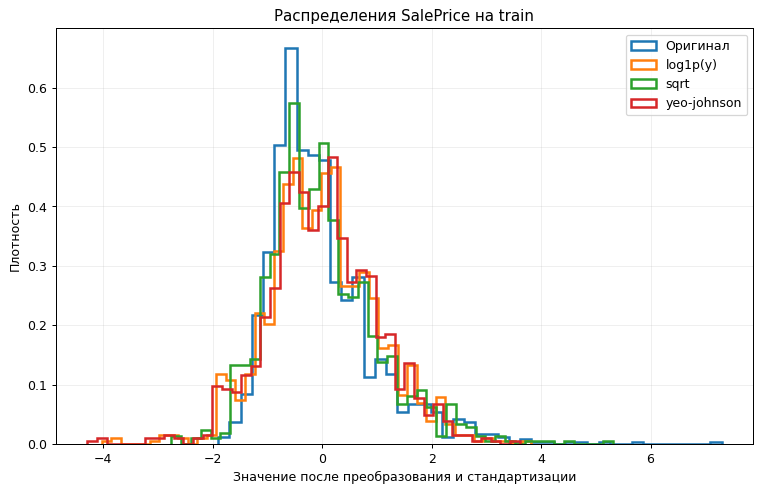

In [13]:
transforms = apply_transformations(y_train)
fig, ax = plt.subplots(figsize=(10, 6))
for name, (values, inverse, forward) in transforms.items():
    assert np.allclose(inverse(forward(y_train)), y_train)
    standardized = (values - values.mean()) / values.std()
    ax.hist(standardized, bins=45, density=True, histtype="step",
            linewidth=2, label=name)
ax.set_xlabel("Значение после преобразования и стандартизации")
ax.set_ylabel("Плотность")
ax.set_title("Распределения SalePrice на train")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## Калибровка на реальных данных

Для хорошо откалиброванной модели среди объектов с вероятностью около 0,8 доля положительных меток близка к 80%. Проверим это по калибровочным кривым, Brier Score и Log Loss. Последние две метрики отражают также способность модели различать объекты, поэтому одного их значения недостаточно для диагноза калибровки.

### Задание 6 [2 балла]

Выбери три датасета бинарной классификации. Можно взять Breast Cancer, два класса Wine и два класса Digits из sklearn.

Для каждого датасета выдели train/test со стратификацией. Обучи библиотечную `LogisticRegression` (импортируй как `SklearnLogReg`, чтобы сохранить свой класс) и `SVC(probability=True)`. Масштабирование выполняй внутри Pipeline.

Для каждой модели сравни исходные вероятности с результатами `CalibratedClassifierCV` при `method='sigmoid'` и `method='isotonic'`. Передавай внутрь калибратора весь pipeline, чтобы scaler обучался заново внутри фолдов. Используй одну test для всех вариантов. Посчитай Brier Score и Log Loss и опиши, где метрики улучшились или ухудшились.

`SVC(probability=True)` уже использует внутреннюю сигмоидную калибровку. Его исходный вариант означает «без дополнительной внешней калибровки». При внешней калибровке можно использовать `SVC(probability=False)`, поскольку CalibratedClassifierCV работает с decision_function. Не делай вывод о причине изменения только по названию датасета.


Breast Cancer, LogisticRegression:
  sigmoid: ΔBrier = +0.009990; ΔLog Loss = +0.047812
  isotonic: ΔBrier = -0.003689; ΔLog Loss = -0.013927

Breast Cancer, SVC:
  sigmoid: ΔBrier = +0.005718; ΔLog Loss = +0.030382
  isotonic: ΔBrier = -0.000805; ΔLog Loss = -0.005662

Wine (0/1), LogisticRegression:
  sigmoid: ΔBrier = +0.018026; ΔLog Loss = +0.093334
  isotonic: ΔBrier = -0.001170; ΔLog Loss = -0.022576

Wine (0/1), SVC:
  sigmoid: ΔBrier = +0.018865; ΔLog Loss = +0.106214
  isotonic: ΔBrier = -0.003279; ΔLog Loss = -0.023525

Digits (0/1), LogisticRegression:
  sigmoid: ΔBrier = +0.006126; ΔLog Loss = +0.050800
  isotonic: ΔBrier = +0.001489; ΔLog Loss = +0.003245

Digits (0/1), SVC:
  sigmoid: ΔBrier = +0.004342; ΔLog Loss = +0.037396
  isotonic: ΔBrier = -0.001113; ΔLog Loss = -0.012774


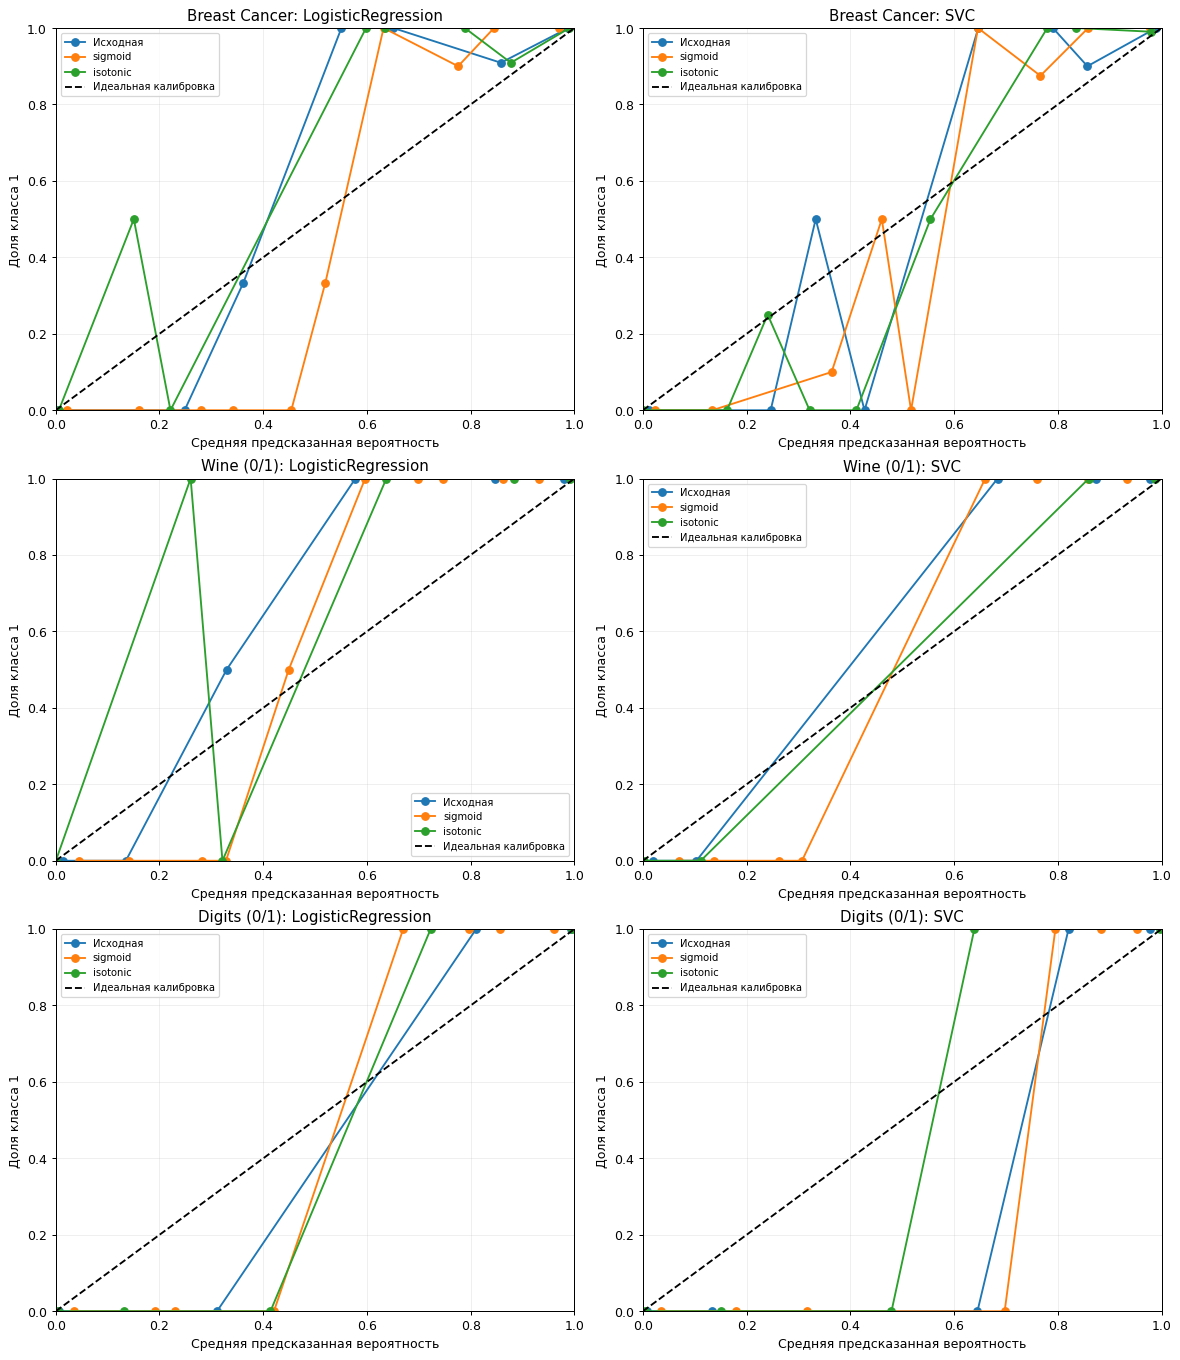

,Датасет,Модель,Калибровка,Brier Score,Log Loss
0,Breast Cancer,LogisticRegression,Исходная,0.017025,0.065536
1,Breast Cancer,LogisticRegression,sigmoid,0.027015,0.113347
2,Breast Cancer,LogisticRegression,isotonic,0.013336,0.051609
3,Breast Cancer,SVC,Исходная,0.019827,0.075837
4,Breast Cancer,SVC,sigmoid,0.025544,0.106218
5,Breast Cancer,SVC,isotonic,0.019021,0.070175
6,Wine (0/1),LogisticRegression,Исходная,0.022081,0.088479
7,Wine (0/1),LogisticRegression,sigmoid,0.040106,0.181813
8,Wine (0/1),LogisticRegression,isotonic,0.020911,0.065903
9,Wine (0/1),SVC,Исходная,0.004580,0.038720


In [14]:
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression as SklearnLogReg
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import brier_score_loss, log_loss

wine = load_wine()
digits = load_digits()
cancer = load_breast_cancer()
datasets = {
    "Breast Cancer": (cancer.data, cancer.target),
    "Wine (0/1)": (wine.data[wine.target < 2], wine.target[wine.target < 2]),
    "Digits (0/1)": (digits.data[digits.target < 2], digits.target[digits.target < 2])
}
calibration_rows = []
calibration_predictions = {}
fig, axes = plt.subplots(3, 2, figsize=(13, 15), constrained_layout=True)
for row, (dataset_name, (X_data, y_data)) in enumerate(datasets.items()):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_data, y_data, test_size=0.3, random_state=42, stratify=y_data)
    cv_cal = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    estimators = {
        "LogisticRegression": SklearnLogReg(max_iter=2000, random_state=42),
        "SVC": SVC(probability=True, random_state=42)
    }
    for col, (model_name, estimator) in enumerate(estimators.items()):
        ax = axes[row, col]
        for method in ["Исходная", "sigmoid", "isotonic"]:
            # SVC уже имеет внутреннюю калибровку; внешняя работает с decision_function.
            base = clone(estimator)
            if model_name == "SVC" and method != "Исходная":
                base.set_params(probability=False)
            pipe = make_pipeline(StandardScaler(), base)
            if method == "Исходная":
                fitted = pipe.fit(X_tr, y_tr)
            else:
                fitted = CalibratedClassifierCV(
                    pipe, method=method, cv=cv_cal, ensemble=True
                ).fit(X_tr, y_tr)
            probabilities = fitted.predict_proba(X_te)[:, 1]
            calibration_predictions[(dataset_name, model_name, method)] = (y_te, probabilities)
            calibration_rows.append({
                "Датасет": dataset_name, "Модель": model_name, "Калибровка": method,
                "Brier Score": brier_score_loss(y_te, probabilities),
                "Log Loss": log_loss(y_te, probabilities)
            })
            fraction, mean_probability = calibration_curve(
                y_te, probabilities, n_bins=10, strategy="uniform")
            ax.plot(mean_probability, fraction, "o-", label=method)
        ax.plot([0, 1], [0, 1], "k--", label="Идеальная калибровка")
        ax.set(xlim=(0, 1), ylim=(0, 1), title=f"{dataset_name}: {model_name}",
               xlabel="Средняя предсказанная вероятность", ylabel="Доля класса 1")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
plt.show()
calibration_results = pd.DataFrame(calibration_rows)
display(calibration_results.round(6))

# Отрицательная разность означает улучшение метрики относительно исходной модели.
for (dataset_name, model_name), group in calibration_results.groupby(["Датасет", "Модель"], sort=False):
    baseline = group[group["Калибровка"] == "Исходная"].iloc[0]
    print(f"\n{dataset_name}, {model_name}:")
    for _, result in group[group["Калибровка"] != "Исходная"].iterrows():
        print(f"  {result['Калибровка']}: ΔBrier = {result['Brier Score'] - baseline['Brier Score']:+.6f}; "
              f"ΔLog Loss = {result['Log Loss'] - baseline['Log Loss']:+.6f}")


**Вывод.** На выбранных разбиениях sigmoid ухудшила Brier Score и Log Loss для обеих моделей на всех трёх датасетах. Isotonic улучшила обе метрики у обеих моделей на Breast Cancer и Wine, а также у SVC на Digits. Исключение — LogisticRegression на Digits: Brier Score вырос с 0,001437 до 0,002926, Log Loss — с 0,011500 до 0,014745. Таблица и разности метрик выше показывают изменения для каждого датасета и модели: отрицательная разность означает улучшение, положительная — ухудшение. Внешняя калибровка не гарантирует улучшения на test. Sigmoid подбирает два параметра, а isotonic задаёт более гибкую монотонную функцию и на небольших калибровочных фолдах может переобучаться. Вероятности isotonic, близкие к 0 или 1, при ошибках особенно сильно увеличивают Log Loss.

Оценивать результат нужно одновременно по кривым и обеим метрикам. На малых test в некоторых интервалах мало объектов, поэтому отклонения кривой от диагонали могут быть случайными. Внешние калибраторы здесь являются ансамблями из пяти моделей, обученных на частях train; исходная модель обучена на всём train. Поэтому изменения связаны не только с преобразованием вероятностей, но и со схемой обучения и усреднением. У исходного SVC уже включена внутренняя калибровка. Выводы относятся к выбранному разбиению, а не доказывают превосходство метода на любых данных.

## Калибровка методом Platt scaling

В заданиях со звёздочкой реализуй калибровку Платта и сравни её с простым преобразованием оценки SVM в диапазон [0, 1]. Оценивание этих заданий входит в общий максимум 10 баллов.

### Задание 7* [1 балл]

Реализуй калибровку Платта для бинарных меток 0/1 или −1/+1. Используй

$$p_i=\frac{1}{1+\exp(Af_i+B)},\qquad L=-\sum_i[t_i\log p_i+(1-t_i)\log(1-p_i)].$$

Здесь $f_i$ является оценкой базовой модели на объектах, которые не участвовали в её обучении. Сглаженные цели равны $(N_++1)/(N_++2)$ для положительных меток и $1/(N_-+2)$ для отрицательных. $N_+$ и $N_-$ являются числом положительных и отрицательных меток калибровочной выборки.

Минимизируй отрицательное логарифмическое правдоподобие по A и B. Для устойчивости используй `np.logaddexp`, проверь успешность оптимизации. Подробности: [Platt scaling и численная реализация](https://www.csie.ntu.edu.tw/~cjlin/papers/plattprob.pdf).

In [15]:
from scipy.optimize import minimize
from scipy.special import expit

class PlattCalibration:
    def __init__(self):
        self.A = None
        self.B = None

    def _calc_t(self, y_array):
        y_array = np.asarray(y_array).ravel()
        labels = set(np.unique(y_array))
        if labels not in ({0, 1}, {-1, 1}):
            raise ValueError("Нужны оба класса с метками 0/1 или -1/+1")
        positive = y_array == 1
        n_positive = positive.sum()
        n_negative = (~positive).sum()
        return np.where(positive, (n_positive + 1) / (n_positive + 2),
                        1 / (n_negative + 2))

    def _sigmoid(self, f, A, B):
        return expit(-(A * np.asarray(f, dtype=float) + B))

    def _neg_log_likelihood(self, params, f, y_array):
        t = self._calc_t(y_array)
        z = params[0] * np.asarray(f, dtype=float).ravel() + params[1]
        # p = sigmoid(-z), поэтому BCE = log(1 + exp(z)) - (1 - t)*z.
        return float(np.sum(np.logaddexp(0, z) - (1 - t) * z))

    def fit(self, f, y_array):
        f = np.asarray(f, dtype=float).ravel()
        y_array = np.asarray(y_array).ravel()
        if len(f) != len(y_array) or not np.all(np.isfinite(f)):
            raise ValueError("Оценки должны быть конечными и совпадать по длине с y")
        t = self._calc_t(y_array)
        n_positive = np.sum(y_array == 1)
        n_negative = len(y_array) - n_positive
        initial = np.array([0., np.log((n_negative + 1) / (n_positive + 1))])

        def gradient(params):
            error = t - self._sigmoid(f, *params)
            return np.array([np.dot(error, f), error.sum()])

        result = minimize(self._neg_log_likelihood, initial, args=(f, y_array),
                          jac=lambda params, *_: gradient(params), method="BFGS",
                          options={"maxiter": 2000, "gtol": 1e-6})
        if not result.success or not np.all(np.isfinite(result.x)):
            raise RuntimeError(f"Оптимизация не сошлась: {result.message}")
        self.A, self.B = result.x
        self.optimization_result_ = result
        return self

    def predict_proba(self, f):
        if self.A is None or self.B is None:
            raise ValueError("Сначала вызови fit")
        return self._sigmoid(f, self.A, self.B)


Проверь реализацию Platt scaling на assert-тесте.

In [16]:
import numpy as np

model = PlattCalibration()

# Проверка _calc_t
t_pm1 = model._calc_t(np.array([-1, 1, -1]))
assert np.allclose(t_pm1, np.array([1/4, 2/3, 1/4])), "Ошибка: _calc_t неправильно сглаживает целевые метки"
print("Модуль _calc_t работает корректно")

# Проверка _sigmoid
p = model._sigmoid(np.array([-2.0, 0.0, 2.0]), A=1, B=0)
expected = 1 / (1 + np.exp(np.array([-2.0, 0.0, 2.0])))
assert np.allclose(p, expected), "Ошибка: сигмоида рассчитывается некорректно"
print("Модуль _sigmoid работает корректно")

# Проверка _neg_log_likelihood
loss = model._neg_log_likelihood([1, 0], np.array([-2.0, 0.0, 2.0]), np.array([-1, 1, -1]))
assert isinstance(loss, float), "Ошибка: _neg_log_likelihood должна возвращать число"
assert loss > 0, "Ошибка: значение функции потерь должно быть положительным"
print("Модуль _neg_log_likelihood работает корректно")

# Проверка fit
model.fit(np.array([-2.0, 0.0, 2.0]), np.array([-1, 1, -1]))
assert model.A is not None, "Ошибка: параметр A не определён после обучения"
assert model.B is not None, "Ошибка: параметр B не определён после обучения"
print("Модуль fit работает корректно")

# Проверка predict_proba
f_test = np.array([-1.5, 0.5, 1.5])
probs = model.predict_proba(f_test)
assert probs.shape == f_test.shape, "Ошибка: форма выходов predict_proba должна совпадать с входами"
assert np.all((probs >= 0) & (probs <= 1)), "Ошибка: вероятности должны быть в диапазоне [0, 1]"
print("Модуль predict_proba работает корректно")

print("Все тесты пройдены")

Модуль _calc_t работает корректно
Модуль _sigmoid работает корректно
Модуль _neg_log_likelihood работает корректно
Модуль fit работает корректно
Модуль predict_proba работает корректно
Все тесты пройдены


In [17]:
# Проверка обоих кодирований меток и численной устойчивости.
f = np.array([-3., -2., -1., 1., 2., 3.])
y01 = np.array([0, 0, 0, 1, 1, 1])
p01 = PlattCalibration().fit(f, y01)
pm1 = PlattCalibration().fit(f, 2*y01 - 1)
assert np.allclose(p01.predict_proba(f), pm1.predict_proba(f))
assert np.all(np.diff(p01.predict_proba(f)) > 0)
assert np.isfinite(p01._neg_log_likelihood([1., 0.], np.array([-1e4, 1e4]), [0, 1]))
assert np.all(np.isfinite(p01.predict_proba(np.array([-1e4, 1e4]))))
print("Дополнительные проверки PlattCalibration пройдены")

Дополнительные проверки PlattCalibration пройдены


### Задание 8* [1 балл]

Обучи SVM на каждом обучающем фолде, а свой PlattCalibration на оценках соответствующего валидационного фолда. На общей test усредни прогнозы этих пар SVM и калибратор. Это ансамбль моделей, построенных на CV-фолдах.

Для сравнения усредни `expit(decision_function)` тех же SVM. Это условная вероятностная шкала без подбора A и B, а не вероятности, которые выдаёт сам SVM. Нельзя заменять её жёсткими метками классов и называть «вероятностями SVM».

Добавь библиотечную логистическую регрессию, обученную на всём train. Для трёх вариантов рассчитай Brier Score и Log Loss и построй калибровочные кривые. Масштабирование SVM обучай отдельно внутри каждого фолда.

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder
from scipy.special import expit

data = fetch_openml(data_id=4534, as_frame=True)
X = data.data.to_numpy(dtype=float)
y = LabelEncoder().fit_transform(data.target.astype(str))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

Для отрисовки графиков можешь дописать функцию или создать свою.

In [ ]:
def mult_plot_calibration_curve(y_test, preds_list, labels):
    # Для каждой серии раздели [0, 1] на 10 интервалов.
    # Последний интервал включает 1. Пустые интервалы пропускай.
    # По X откладывай среднюю вероятность внутри интервала,
    # по Y долю положительных меток, затем добавь диагональ.
    # Можно использовать sklearn.calibration.calibration_curve.
    raise NotImplementedError

In [ ]:
# Напиши код здесь

**Вопрос.** Сравни вероятностные метрики и кривые для среднего sigmoid(score), среднего прогноза после Platt и логистической регрессии. Где калибровка улучшила результат, а где ухудшила? Какой вывод можно сделать на этой test?

Теперь ты знаешь:
- как реализовывать собственную векторизованную логистическую регрессию, обучать её на реальных данных и визуализировать разделяющие границы;
- исследовать, как различные преобразования целевой переменной влияют на качество линейных и древовидных моделей регрессии, и делать выводы о целесообразности этих трансформаций;
- проверять, как калибровка вероятностей (Platt scaling и изотоническая регрессия) влияют на метрики качества прогнозов для разных моделей и датасетов;
- реализовывать метод Platt scaling с нуля и сравнивать качество вероятностных прогнозов моделей до и после калибровки, визуализировать калибровочные кривые и анализировать, где калибровка наиболее полезна.